Dataset loaded!
Shape= (50000, 2)
Dataset Information=
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     50000 non-null  str  
 1   sentiment  50000 non-null  str  
dtypes: str(2)
memory usage: 781.4 KB
None

Missing Values=
review       0
sentiment    0
dtype: int64

Sentiment Distribution=
sentiment
positive    25000
negative    25000
Name: count, dtype: int64

Duplicate Reviews=
418

Unique Sentiment Labels=
<StringArray>
['positive', 'negative']
Length: 2, dtype: str


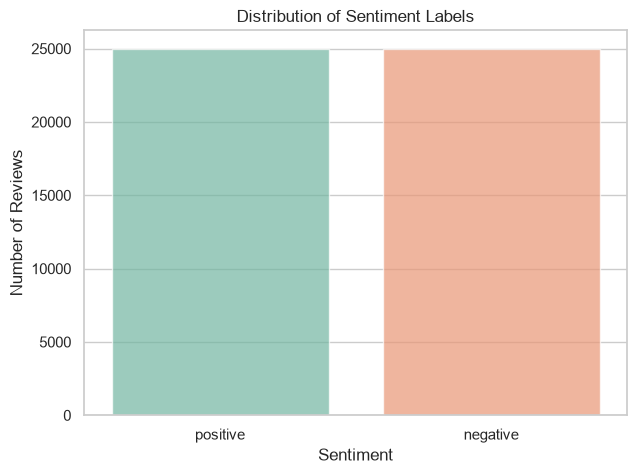

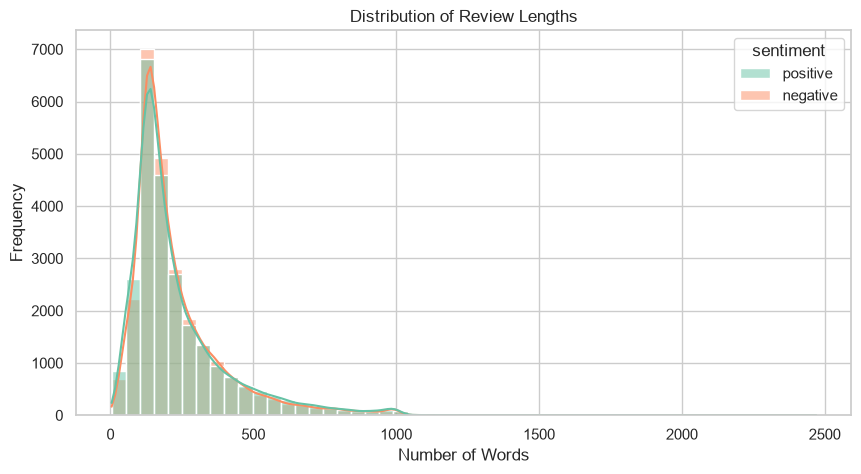

In [ ]:
#PHASE A- EXPLORATORY DATA ANALYSIS
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
import os
from pathlib import Path
RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
DATA_PATH = Path.cwd() / "data" / "raw" / "IMDB Dataset.csv"
df = pd.read_csv(DATA_PATH)
print("Dataset loaded!")

print("Shape=", df.shape)
df.head()
print("Dataset Information=")
print(df.info())
print("\nMissing Values=")
print(df.isnull().sum())
print("\nSentiment Distribution=")
print(df["sentiment"].value_counts())
print("\nDuplicate Reviews=")
print(df["review"].duplicated().sum())
print("\nUnique Sentiment Labels=")
print(df["sentiment"].unique())

plt.figure(figsize=(7, 5))
sns.countplot(data=df,x="sentiment", palette="Set2", hue="sentiment", alpha=0.7, legend=False) #legend=False to remove legend
plt.title("Distribution of Sentiment Labels")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()

df["review_length"] = df["review"].astype(str).apply(lambda x: len(x.split()))
plt.figure(figsize=(10, 5))
sns.histplot(data=df,x="review_length",hue="sentiment",bins=50,kde=True, palette="Set2", alpha=0.5)
plt.title("Distribution of Review Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.show()

In [4]:
duplicate_count = df.duplicated(subset=["review"]).sum()
unique_reviews = df["review"].nunique()
conflicts = (df.groupby("review")["sentiment"].nunique())
conflicting_reviews = (conflicts > 1).sum()
print("Duplicate review rows:", duplicate_count)
print("Unique review texts:", unique_reviews)
print("Conflicting-label review texts:", conflicting_reviews)

Duplicate review rows: 418
Unique review texts: 49582
Conflicting-label review texts: 0



# Phase B: Dataset Splitting and Leakage Prevention
## Objective- Divide the original IMDB dataset into training and testing partitions.
## Splitting Strategy
-Training set: 40,000 reviews (80%)
- Testing set: 10,000 reviews (20%)
- Random seed: 42
- Positive and negative classes will remain balanced.
- Identical review texts will not cross partition boundaries.
- All original rows will be retained.

## Data Leakage Prevention
Duplicate reviews will be assigned to the same partition to prevent identical text from appearing in both training and testing datasets.


In [ ]:
import pandas as pd
import numpy as np
RANDOM_STATE = 42
groups = (df.groupby("review", as_index=False).agg(sentiment=("sentiment", "first"),row_count=("sentiment", "size")))
train_reviews = set()
test_reviews = set()
for sentiment in ["positive", "negative"]:
    class_groups = groups[groups["sentiment"] == sentiment].copy() 
duplicate_groups = class_groups[class_groups["row_count"] > 1]
single_groups = class_groups[class_groups["row_count"] == 1]
train_reviews.update(duplicate_groups["review"])
test_sample = single_groups.sample(n=5000,random_state=RANDOM_STATE)
test_reviews.update(test_sample["review"])
remaining_groups = single_groups[~single_groups["review"].isin(test_reviews)]
train_reviews.update(remaining_groups["review"])
# Create the actual datasets
train_df = df[df["review"].isin(train_reviews)].copy()
test_df = df[df["review"].isin(test_reviews)].copy()
print("Split generated successfully.")


Split generated successfully.


In [12]:

print("TRAINING ROWS:", len(train_df))
print("TESTING ROWS:", len(test_df))
print("\nTRAINING DISTRIBUTION:")
print(train_df["sentiment"].value_counts())
print("\nTESTING DISTRIBUTION:")
print(test_df["sentiment"].value_counts())
print("\nDUPLICATE OVERLAP:",len(set(train_df["review"]) & set(test_df["review"])))
print("\nTOTAL ROWS:", len(train_df) + len(test_df))
print("ORIGINAL ROWS:", len(df))
checks = {
    "Training rows": len(train_df) == 40000,
    "Testing rows": len(test_df) == 10000,
    "Training positive": (train_df["sentiment"] == "positive").sum() == 20000,
    "Training negative": (train_df["sentiment"] == "negative").sum() == 20000,
    "Testing positive": (test_df["sentiment"] == "positive").sum() == 5000,
    "Testing negative": (test_df["sentiment"] == "negative").sum() == 5000,
    "No duplicate leakage": set(train_df["review"]).isdisjoint(set(test_df["review"])),
    "All rows retained": len(train_df) + len(test_df) == len(df)
}
print("\nINDIVIDUAL VALIDATION:")
for check, result in checks.items():
    print(f"{check}: {'PASS' if result else 'FAIL'}")

assert all(checks.values()), "Split validation failed!"
print("\nALL CHECKS PASSED!")


TRAINING ROWS: 40000
TESTING ROWS: 10000

TRAINING DISTRIBUTION:
sentiment
positive    20000
negative    20000
Name: count, dtype: int64

TESTING DISTRIBUTION:
sentiment
positive    5000
negative    5000
Name: count, dtype: int64

DUPLICATE OVERLAP: 0

TOTAL ROWS: 50000
ORIGINAL ROWS: 50000

INDIVIDUAL VALIDATION:
Training rows: PASS
Testing rows: PASS
Training positive: PASS
Training negative: PASS
Testing positive: PASS
Testing negative: PASS
No duplicate leakage: PASS
All rows retained: PASS

ALL CHECKS PASSED!


In [ ]:
from pathlib import Path
PROCESSED_DIR = Path("data/processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
train_df.to_csv(PROCESSED_DIR / "train.csv", index=False)
test_df.to_csv(PROCESSED_DIR / "test.csv", index=False)
print("Training and testing datasets saved successfully!")

Training and testing datasets saved successfully!


In [ ]:
from pathlib import Path
processed_dir = Path("data/processed")
processed_dir.mkdir(parents=True, exist_ok=True)
train_df.to_csv(processed_dir / "train.csv", index=False)
test_df.to_csv(processed_dir / "test.csv", index=False)
print("Correct save location:", processed_dir.resolve())
print("Files:", [f.name for f in processed_dir.iterdir()])


Correct save location: C:\Users\VRINDA ARORA\OneDrive\Desktop\Sentient-Beings-Review-Sentiment\data\processed
Files: ['test.csv', 'train.csv']


In [1]:
import json
from pathlib import Path
metadata = {
    "phase": "A",
    "seed": 42,
    "train_rows": 40000,
    "test_rows": 10000,
    "train_positive": 20000,
    "train_negative": 20000,
    "test_positive": 5000,
    "test_negative": 5000,
    "duplicate_review_rows_after_first": 418,
    "conflicting_label_review_texts": 0,
    "duplicate_policy": (
        "Retain all original rows; identical review texts "
        "are assigned entirely to training to prevent train-test leakage."),
    "test_usage": (
        "Locked until Phase D; no training, tuning, or "
        "preprocessing decisions on test data."
    )
}

with open("../split_metadata.json", "w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=4)
print("Phase A metadata updated!")

Phase A metadata updated!
